# 02 - Treatment Assignment, Causal DAG, and ATE Estimation

Answers Section 6 of the assignment: does treatment look randomized, what does the causal graph imply
about identifiability, and what is the campaign's Average Treatment Effect under four primary estimators
and a stabilized-IPW robustness check?

In [1]:
import pandas as pd
from IPython.display import Image, display
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 140)
from src.utils.config import TABLES_DIR, FIGURES_DIR, REPORT_DIR

## 6.1 — Treatment Assignment Analysis: Covariate Balance (SMD)

In [2]:
pd.read_csv(TABLES_DIR / "covariate_balance_smd.csv")

,feature,mean_treated,mean_control,std_treated,std_control,smd,abs_smd,balanced_lt_0.1
0,f3,4.169413,4.232820,1.359441,1.244250,-0.048658,0.048658,True
1,f6,-4.182793,-3.999880,4.556964,4.447072,-0.040626,0.040626,True
2,f5,4.026601,4.039339,0.421851,0.407912,-0.030699,0.030699,True
3,f9,16.052595,15.886253,6.835747,6.792237,0.024412,0.024412,True
4,f7,5.105551,5.080285,1.304124,1.157138,0.020495,0.020495,True
5,f8,3.933395,3.934652,0.084686,0.073170,-0.015886,0.015886,True
6,f0,19.614763,19.651701,5.447853,5.398869,-0.006811,0.006811,True
7,f1,10.070338,10.067936,0.537629,0.107675,0.006196,0.006196,True
8,f11,-0.170985,-0.170868,0.028189,0.022546,-0.004585,0.004585,True
9,f2,8.446307,8.448173,0.487002,0.309533,-0.004574,0.004574,True


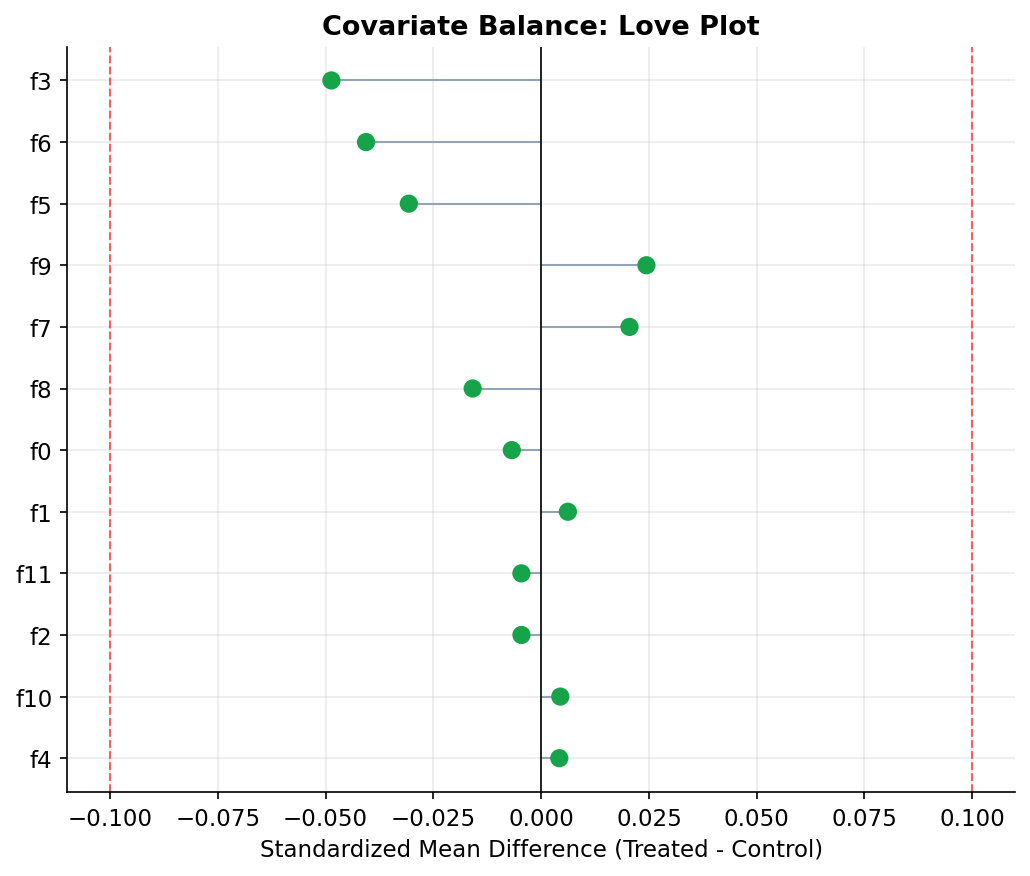

In [3]:
display(Image(filename=str(FIGURES_DIR / "smd_love_plot.png")))

## 6.1 — Can Customer Features Predict Treatment Assignment?

In [4]:
import json
results = json.loads((REPORT_DIR / "phase1_results.json").read_text())
results["treatment_assignment_verdict"]

{'auc': 0.5094072145325999,
 'n_features_imbalanced_smd_gt_0.1': 0,
 'max_abs_smd': 0.04865819315103917,
 'looks_randomized': True}

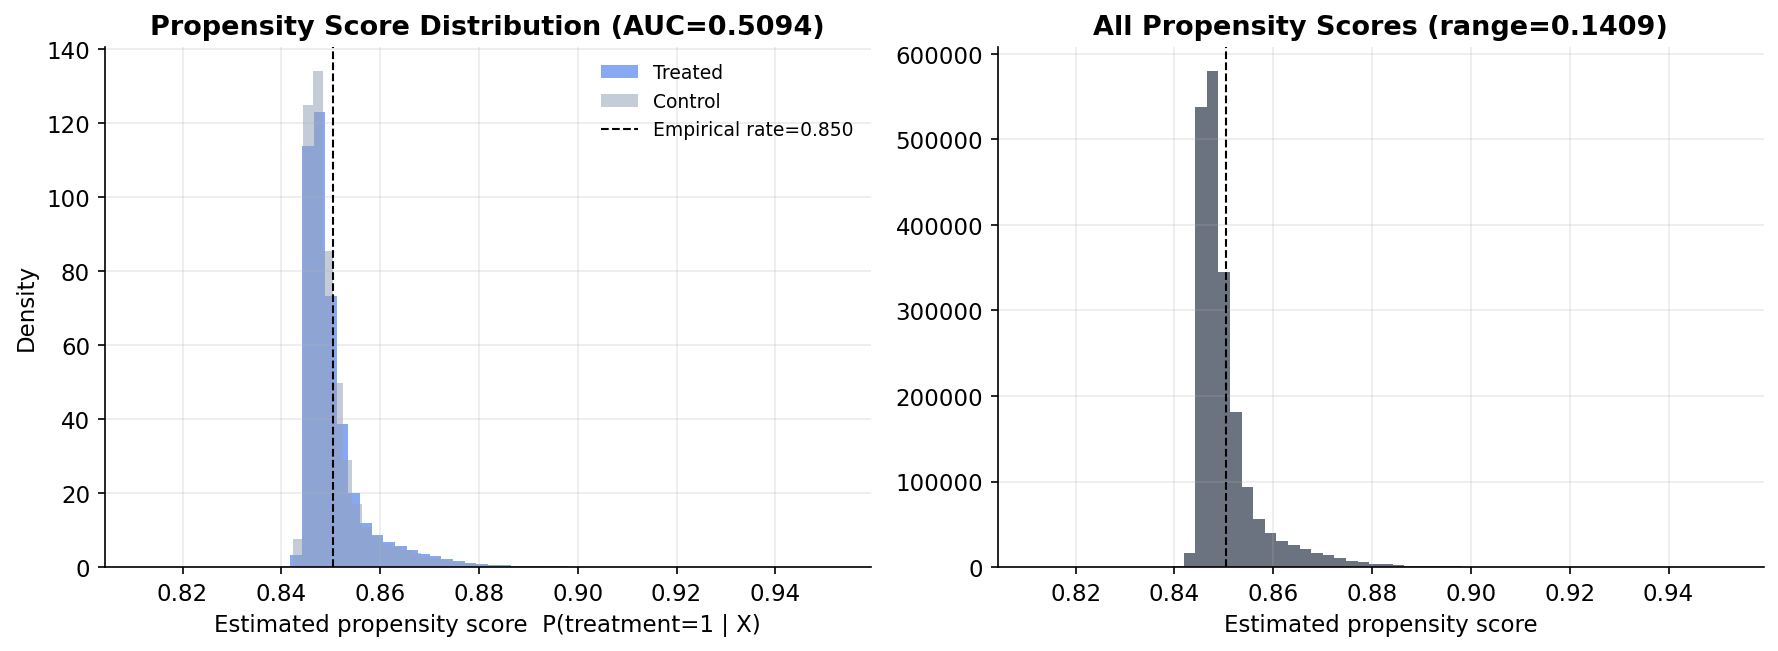

In [5]:
display(Image(filename=str(FIGURES_DIR / "propensity_score_diagnostics.png")))

Treatment assignment is consistent with randomization. All 12 covariates have |SMD| < 0.1, and a logistic
regression predicting treatment from those covariates has AUC 0.509. Estimated propensity scores for both
arms are concentrated near the empirical treatment rate of 0.85.

## 6.2 — Causal DAG

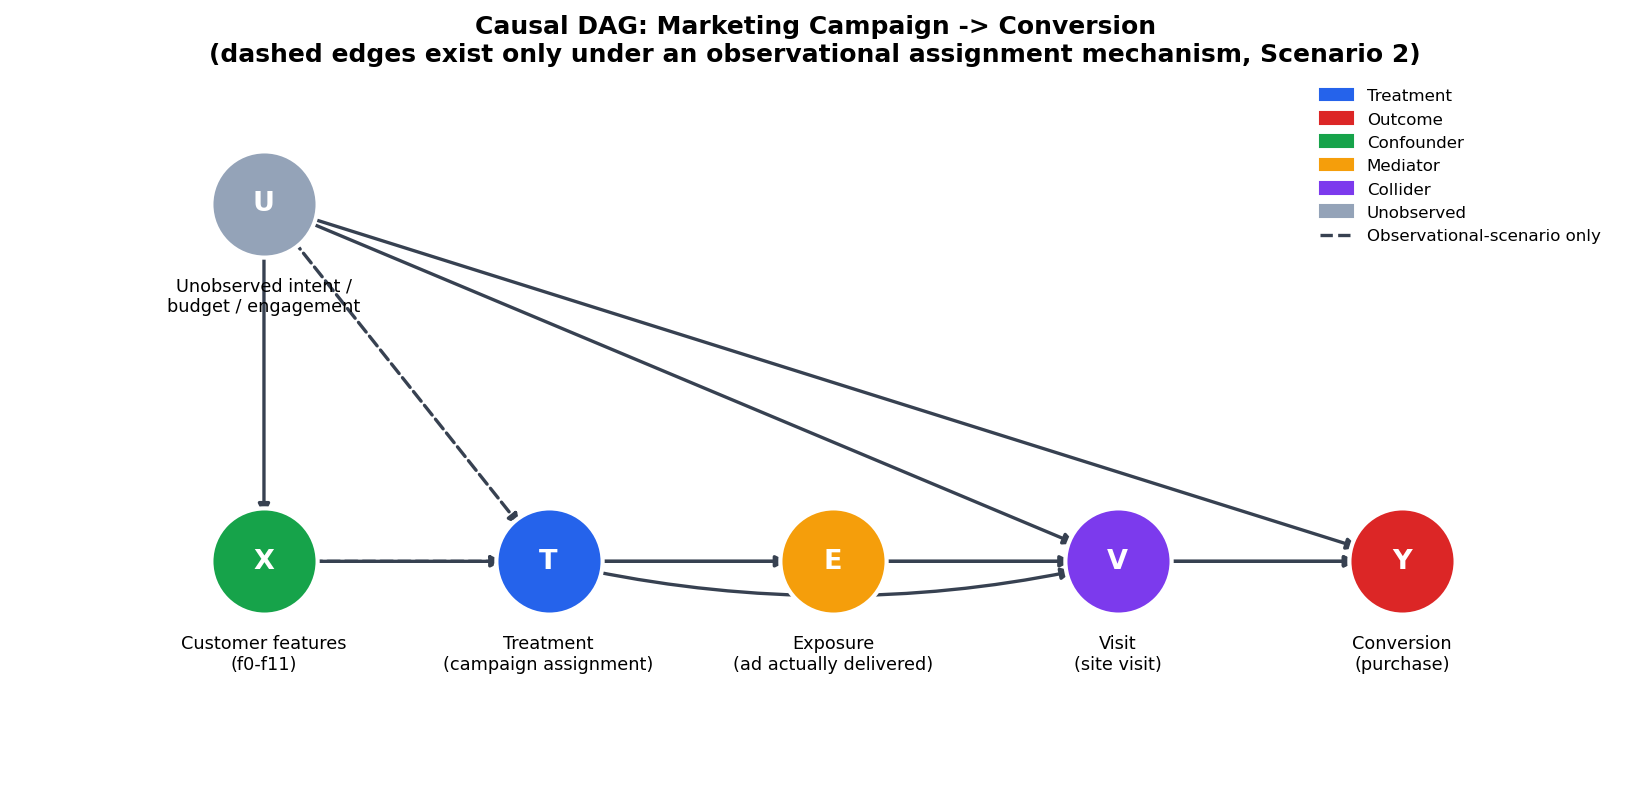

In [6]:
display(Image(filename=str(FIGURES_DIR / "causal_dag.png")))

In [7]:
dag_discussion = json.loads((REPORT_DIR / "dag_discussion.json").read_text())
for k, v in dag_discussion.items():
    print(f"### {k}\n{v}\n")

### confounders
X (the 12 anonymized customer features) is the primary *observed* confounder candidate: if it affects both who gets treated (in an observational assignment mechanism) and the outcome, it opens a back-door path T <- X -> Y that must be closed by adjustment (regression adjustment / IPW / DR). U (unobserved intent, budget, engagement) is a potential *unobserved* confounder -- if it affects both assignment and outcome, no amount of adjustment on X alone identifies the effect; this is the key threat to validity in the observational scenario discussed in Section 6.3.

### mediators
E (exposure -- whether the ad was actually delivered/seen) and V (site visit) both sit on the causal path FROM the campaign TO conversion: T -> E -> V -> Y. They explain *how* the campaign works, but must never be conditioned on when estimating the causal effect of T on Y -- adjusting for a mediator blocks part of the very effect being measured and biases the estimate toward zero (this is why the A

## 6.3 — Observable vs. Unobservable Confounding: Two Scenarios

### Scenario 1: randomized treatment

With randomized treatment, Difference-in-Means identifies the ATE without covariate adjustment. Regression
and propensity-based estimators are included as precision adjustments and robustness checks.

### Scenario 2: observational targeting

If targeting depends on `X`, the path `T <- X -> Y` is open and unadjusted Difference-in-Means can be
biased. Regression adjustment, IPW, and AIPW require measured covariates to capture the confounding. The
semi-synthetic experiment below changes sample retention while preserving the original randomized outcomes.

## 6.4 — Estimator Comparison (on the REAL, randomized data)

In [8]:
pd.read_csv(TABLES_DIR / "ate_estimators_conversion.csv")

,method,ate,se,ci_low,ci_high,ci_width,n,n_treated,n_control,note,max_weight_treated,max_weight_control,effective_n_treated,effective_n_control
0,Difference in Means,0.001152,0.000034,0.001085,0.001219,0.000135,13979592,11882655.0,2096937.0,NaN,NaN,NaN,NaN,NaN
1,Regression Adjustment,0.000983,0.000002,0.000979,0.000986,0.000006,13979592,NaN,NaN,plug-in variance; ignores first-stage nuisance...,NaN,NaN,NaN,NaN
2,IPW (Horvitz-Thompson),0.000991,0.000036,0.000920,0.001062,0.000142,13979592,NaN,NaN,NaN,1.250883,12.772913,1.188191e+07,2.092165e+06
3,Doubly Robust (AIPW),0.000966,0.000034,0.000898,0.001033,0.000135,13979592,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,"IPW (Hajek, stabilized)",0.000991,0.000036,0.000920,0.001062,0.000142,13979592,NaN,NaN,IF variance conditional on fitted propensity s...,NaN,NaN,NaN,NaN


In [9]:
pd.read_csv(TABLES_DIR / "ate_estimators_visit.csv")

,method,ate,se,ci_low,ci_high,ci_width,n,n_treated,n_control,note,max_weight_treated,max_weight_control,effective_n_treated,effective_n_control
0,Difference in Means,0.010342,0.000146,0.010056,0.010629,0.000574,13979592,11882655.0,2096937.0,NaN,NaN,NaN,NaN,NaN
1,Regression Adjustment,0.007132,0.000006,0.007120,0.007143,0.000023,13979592,NaN,NaN,plug-in variance; ignores first-stage nuisance...,NaN,NaN,NaN,NaN
2,IPW (Horvitz-Thompson),0.007803,0.000156,0.007497,0.008109,0.000611,13979592,NaN,NaN,NaN,1.250883,12.772913,1.188191e+07,2.092165e+06
3,Doubly Robust (AIPW),0.007147,0.000130,0.006893,0.007401,0.000508,13979592,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,"IPW (Hajek, stabilized)",0.007801,0.000153,0.007502,0.008100,0.000598,13979592,NaN,NaN,IF variance conditional on fitted propensity s...,NaN,NaN,NaN,NaN


The point estimates are similar, as expected under randomization. The Regression Adjustment interval
uses a plug-in variance that omits uncertainty from fitting the outcome models, so it is too narrow for
inference. The AIPW interval is based on its influence function and includes residual outcome variation.

## Synthetic Observational Scenario: Confounding-Injection Ablation

In [10]:
conf_diag = results["confounding_injection_diagnostics"]
conf_diag

{'confounder': 'f4',
 'original_n': 13979592,
 'confounded_n': 2000000,
 'original_treatment_ratio': 0.8500001287591226,
 'confounded_treatment_ratio': 0.8372865,
 'original_smd_confounder': 0.004208012604994589,
 'confounded_smd_confounder': 0.2719985713931862}

In [11]:
pd.read_csv(TABLES_DIR / "ate_estimators_confounded_sample.csv")

,method,ate,se,ci_low,ci_high,ci_width,n,n_treated,n_control,note,max_weight_treated,max_weight_control,effective_n_treated,effective_n_control,bias_vs_target_population_rct
0,Difference in Means,0.004116,0.000075,0.003970,0.004262,0.000292,2000000,1674573.0,325427.0,NaN,NaN,NaN,NaN,NaN,0.002530
1,Regression Adjustment,0.001531,0.000006,0.001520,0.001543,0.000023,2000000,NaN,NaN,plug-in variance; ignores first-stage nuisance...,NaN,NaN,NaN,NaN,-0.000055
2,IPW (Horvitz-Thompson),0.000360,0.000373,-0.000371,0.001091,0.001463,2000000,NaN,NaN,NaN,1.220348,100.0,1.671485e+06,212097.883791,-0.001226
3,Doubly Robust (AIPW),0.001619,0.000351,0.000931,0.002308,0.001377,2000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000033
4,"IPW (Hajek, stabilized)",0.000378,0.000370,-0.000348,0.001103,0.001451,2000000,NaN,NaN,IF variance conditional on fitted propensity s...,NaN,NaN,NaN,NaN,-0.001208


In [12]:
results["confounding_target_population_rct_reference"]

{'estimand': 'ATE in the marginal-retention target population',
 'ate': 0.0015861307462664322,
 'se': 5.0257930249219706e-05,
 'ci_low': 0.0014876270130404353,
 'ci_high': 0.001684634479492429,
 'treated_rate': 0.004386888199004848,
 'control_rate': 0.0028007574527384154,
 'mean_target_weight': 0.48320632593183965,
 'beta': 1.0,
 'z_clip': 2.0}

The retained sample changes the estimand, so the benchmark is the retention-weighted ATE from the original
randomized trial. Weighting by `q(X)=e*s1(X)+(1-e)*s0(X)` targets that same population. Difference-in-Means
is biased after selection, while Regression Adjustment and AIPW are close to the reference. Standalone IPW
is unstable because fitted control weights reach the clipping threshold.

## 6.5 — Interpretation

The estimated conversion ATE is about 0.10 percentage points. Because the control conversion rate is low,
this corresponds to a relative increase of approximately 50% to 59%, depending on the estimator. The
absolute effect and its uncertainty are the relevant inputs for the policy analysis in notebook 04.